<a href="https://colab.research.google.com/github/mhabibier/scikit-learn-cookbook/blob/main/09_Text_Processing_and_Multiclass_Classification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Chapter 9 — Text Processing and Multiclass Classification

**scikit-learn Cookbook, Third Edition — John Sukup (Packt, 2025)**  
**Nama:** Muhammad Habibie Rabbani · **Kelas:** TK-47-04

## Tujuan pembelajaran
Mengubah teks menjadi fitur numerik, menjelaskan BoW/TF-IDF/n-gram/POS, membangun model klasifikasi teks, serta menghindari kebocoran vocabulary dan evaluasi kelas yang tidak pernah dipelajari.

## Peta reproduksi
Notebook ini mengadaptasi notebook bab utama dan *Exercise Solutions* dari [kode pendamping resmi](https://github.com/PacktPublishing/scikit-learn-Cookbook-Third-Edition/tree/c624b1279cf23a83273e806cede15cad0c9e5500), commit `c624b1279cf23a83273e806cede15cad0c9e5500`. Penjelasan ditulis ulang dalam Bahasa Indonesia; kode disesuaikan agar dapat dijalankan pada lingkungan yang dicatat di bawah. Penomoran bagian mengikuti alur konsep sumber, bukan nomor halaman PDF. Buku tetap referensi utama untuk membaca uraian lengkap.

| Resep sumber | Bagian |
|---|---|
| Introduction to text processing | 1–2: movie_reviews subset 500 |
| Text vectorization | 3: Reuters BoW dan TF-IDF |
| Feature extraction | 4: Brown sentences, n-gram dan POS |
| Text classifiers | 5: Brown NB, SVC, logistic |
| Multiclass strategies | 6: Brown OvR dan OvO |
| Evaluation | 7: movie_reviews penuh |
| Exercises 1–3 | 8–9: contoh kecil dan multiclass yang valid |

## Penyesuaian dan batas reproduksi
Korpus NLTK asli dipakai; tidak ada penggantian dengan data sintetis. Matriks sparse tetap sparse, kecuali contoh latihan sangat kecil. Brown dibaca dengan `words()` agar tag POS yang ada pada `raw()` tidak menjadi bagian teks klasifikasi. Metadata label Reuters dipertahankan sebagai multilabel; resep vectorization tidak memerlukan pemaksaan label pertama. Latihan 3 sumber hanya memiliki satu teks per kelas dan melakukan vectorization sebelum split; di sini masalah itu diperlihatkan, lalu latihan klasifikasi diselesaikan memakai subset Brown dengan beberapa dokumen per kelas. Sumber yang menyatakan semua kelas Brown berisi >20 dokumen dikoreksi melalui hitungan aktual.

## Cara menjalankan
Jalankan **Restart Kernel → Run All** dari atas ke bawah. Setiap notebook mandiri. Gunakan Python 3.12 dan paket dalam `requirements.txt`; versi yang benar-benar dipakai tampil di sel pertama. Chapter ini memerlukan internet pada eksekusi pertama untuk mengunduh korpus NLTK; cache dapat dipakai ulang. Jika unduhan gagal, sel berhenti dengan pesan yang jelas dan tidak mengganti data secara diam-diam.

Untuk Google Colab: unggah `.ipynb`, instal versi paket yang diperlukan bila berbeda, lalu **Restart session → Run all**. Pengujian paket ini dilakukan dengan proses IPython baru per notebook, bukan melalui antarmuka Colab.

In [1]:
%matplotlib inline
import sys, platform, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
from IPython.display import display, Markdown
from sklearn.base import clone
from sklearn.pipeline import make_pipeline, Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, GridSearchCV
from sklearn.metrics import accuracy_score, balanced_accuracy_score, classification_report, f1_score

SEED = 2024
np.random.seed(SEED)
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams.update({'figure.figsize': (8, 4.5), 'figure.dpi': 115, 'axes.titlesize': 12})
pd.set_option('display.max_columns', 16)
pd.set_option('display.precision', 4)
print({'Python': platform.python_version(), 'scikit-learn': sklearn.__version__,
       'NumPy': np.__version__, 'pandas': pd.__version__, 'seed': SEED})

def audit_numeric(X, y=None, name='data'):
    frame = pd.DataFrame(X)
    print(name, {'shape': frame.shape, 'missing': int(frame.isna().sum().sum()),
                 'duplicate_rows': int(frame.duplicated().sum()),
                 'all_finite': bool(np.isfinite(frame.to_numpy(dtype=float)).all())})
    if y is not None and np.asarray(y).ndim == 1:
        display(pd.Series(y).value_counts().sort_index().rename('jumlah').to_frame())

def report(y_true, y_pred, names=None):
    result = classification_report(y_true, y_pred, target_names=names, output_dict=True, zero_division=0)
    overall_accuracy = result.pop('accuracy', None)
    display(pd.DataFrame(result).T)
    if overall_accuracy is not None:
        print(f'Overall accuracy: {overall_accuracy:.4f} (n={len(y_true)})')

def metrics(y_true, y_pred):
    return {'accuracy': accuracy_score(y_true, y_pred),
            'balanced_accuracy': balanced_accuracy_score(y_true, y_pred),
            'macro_f1': f1_score(y_true, y_pred, average='macro', zero_division=0)}

{'Python': '3.13.16', 'scikit-learn': '1.6.1', 'NumPy': '2.1.3', 'pandas': '2.2.3', 'seed': 2024}


## 1. Data, cache, dan satuan observasi
Teks belum berupa fitur numerik; langkah umum adalah normalisasi, tokenisasi, pembentukan vocabulary, lalu pembobotan. Lowercasing menyatukan “Data” dan “data”, tetapi dapat menghilangkan informasi nama diri. Stopword removal dapat membantu beberapa tugas namun menghilangkan kata negasi seperti “not” dapat merusak sentimen. Stemming memotong bentuk kata; lemmatization memakai informasi leksikal untuk memperoleh bentuk dasar. Keduanya tidak otomatis diperlukan pada semua dataset.

Unit split untuk klasifikasi berikut adalah **dokumen**, bukan kalimat acak dari dokumen yang sama. Irisan kalimat dari dokumen/penulis yang sama bisa membuat hasil terlalu optimistis. Metadata penulis/waktu yang relevan memerlukan group/temporal split. Korpus lama berbahasa Inggris ini bukan validasi model bahasa Indonesia atau teks masa kini.

Sel data hanya mengunduh resource yang dibutuhkan. Kegagalan download menimbulkan error yang menjelaskan penyebab; jalankan ulang setelah koneksi diperbaiki. Paket korpus tidak disertakan dalam ZIP tugas; atribusi dan syarat penggunaan tetap mengikuti masing-masing korpus NLTK.

In [2]:
import os, json, hashlib, urllib.request, zipfile
from pathlib import Path
from collections import Counter
import nltk
from nltk.corpus import movie_reviews, reuters, brown, stopwords
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import SVC
from sklearn.multiclass import OneVsRestClassifier, OneVsOneClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import ConfusionMatrixDisplay, precision_score, recall_score

cache=Path(os.environ.get('COOKBOOK_NLTK_DATA',str(Path.cwd()/'.nltk_data')))
cache.mkdir(parents=True,exist_ok=True)
nltk.data.path.insert(0,str(cache))
resources={'movie_reviews':'corpora/movie_reviews','reuters':'corpora/reuters.zip',
    'brown':'corpora/brown','punkt_tab':'tokenizers/punkt_tab',
    'averaged_perceptron_tagger_eng':'taggers/averaged_perceptron_tagger_eng','stopwords':'corpora/stopwords'}
# Instalasi manual resmi NLTK: hanya enam URL statis pada commit tetap.
# SHA-256 berasal dari index.xml resmi pada commit yang sama.
DATA_COMMIT='550b6625bcef1f2abff2ff770a5a0d272c9c6b2a'
archives={
 'movie_reviews':('corpora','a41211ae685019137410268134db6a1a14428c89b671eb83056151a878539008'),
 'reuters':('corpora','9a59a43823f02a6e2777075c989a3dc454e4b6f68e0332ee3c0e8264075b62f5'),
 'brown':('corpora','9b275f9b3b95d7bd66ccfb7cd259f445a13bbe5d1f4107aba09fd3e8364bafa6'),
 'punkt_tab':('tokenizers','e57f64187974277726a3417ca6f181ec5403676c717672eef6a748a7b20e0106'),
 'averaged_perceptron_tagger_eng':('taggers','6025f530624335c67d6547d44757b357b4e79bae030a0383e9887a92c1718f0b'),
 'stopwords':('corpora','48c0e52d8b52546e827f53761fb30300c0ab94f70660d28bd65ba0a86270946b')}
for package,(subdir,expected) in archives.items():
    destination=cache/subdir; destination.mkdir(exist_ok=True)
    archive=destination/f'{package}.zip'
    if not archive.exists():
        url=f'https://raw.githubusercontent.com/nltk/nltk_data/{DATA_COMMIT}/packages/{subdir}/{package}.zip'
        try:
            with urllib.request.urlopen(url,timeout=60) as response:
                if response.geturl()!=url: raise RuntimeError('Redirect tidak diharapkan.')
                payload=response.read(20*1024*1024)
        except Exception as exc:
            raise RuntimeError(f'Unduhan NLTK {package} gagal; periksa koneksi ke repository nltk/nltk_data.') from exc
        if hashlib.sha256(payload).hexdigest()!=expected: raise RuntimeError(f'Checksum {package} tidak cocok.')
        archive.write_bytes(payload)
    if hashlib.sha256(archive.read_bytes()).hexdigest()!=expected: raise RuntimeError(f'Cache {package} tidak cocok dengan sumber.')
    if package!='reuters':
        with zipfile.ZipFile(archive) as z:
            for member in z.infolist():
                if not (destination/member.filename).resolve().is_relative_to(destination.resolve()):
                    raise RuntimeError('Path arsip tidak valid.')
            z.extractall(destination)
    nltk.data.find(resources[package])
print('NLTK version:',nltk.__version__)
print({'movie_reviews_documents':len(movie_reviews.fileids()),'Reuters_documents':len(reuters.fileids()),'Brown_documents':len(brown.fileids())})
manifest={p.name:hashlib.sha256(p.read_bytes()).hexdigest() for p in sorted(cache.rglob('*.zip'))}
artifact_dir=Path('artifacts'); artifact_dir.mkdir(exist_ok=True)
(artifact_dir/'ch09_corpus_manifest.json').write_text(json.dumps({'nltk':nltk.__version__,'data_commit':DATA_COMMIT,'sha256':manifest},indent=2))
print('Checksum arsip cache dicatat; korpus tidak dimasukkan ke paket tugas.')

NLTK version: 3.9.1
{'movie_reviews_documents': 2000, 'Reuters_documents': 10788, 'Brown_documents': 500}
Checksum arsip cache dicatat; korpus tidak dimasukkan ke paket tugas.


## 2. Movie reviews: Bag of Words dan audit teks
Bag of Words (BoW) memetakan setiap dokumen ke hitungan token. Kolom adalah vocabulary training, baris adalah dokumen. Urutan kata tidak dipertahankan pada unigram. `fit_transform(training)` mempelajari vocabulary; test harus memakai `transform`, sehingga istilah baru yang tidak dikenal diabaikan.

Kita mengikuti subset 500 dokumen seimbang dari sumber, lalu split 70/30. Plot menampilkan frekuensi token training saja. Penjumlahan sparse dilakukan langsung, bukan mengubah seluruh matriks menjadi dense. Matriks $n\times V$ yang mostly zero lebih hemat disimpan sebagai sparse daripada membutuhkan sekitar $8nV$ byte untuk float64 dense.

{'empty_texts': 0, 'duplicate_texts': 0}


,documents
neg,1000
pos,1000


BoW shapes: (350, 18881) (150, 18881) density: 0.013599461287613399


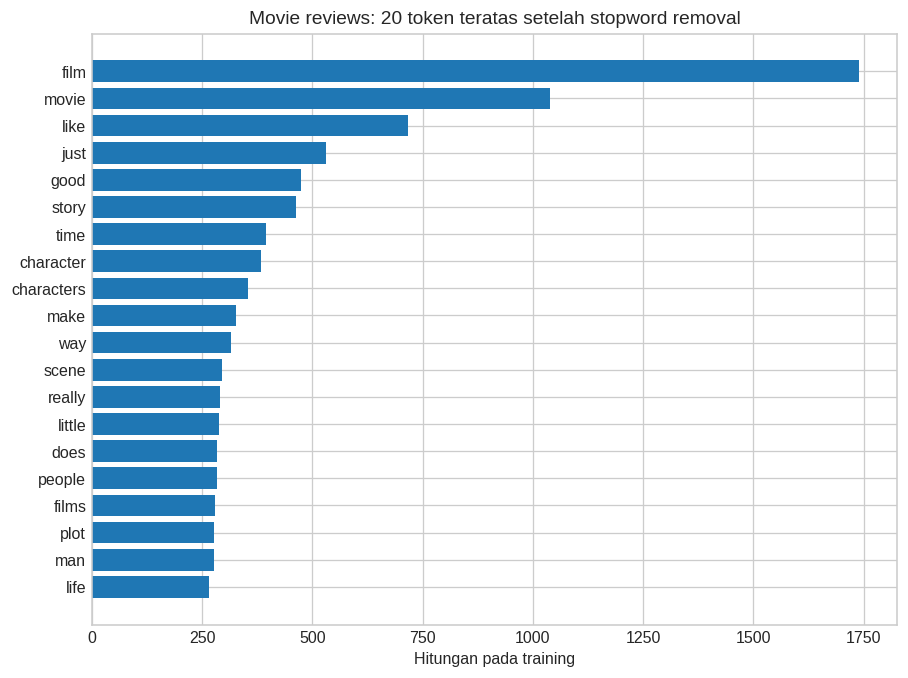

In [3]:
movie_ids=sorted(movie_reviews.fileids())
movie_texts=np.array([' '.join(movie_reviews.words(fid)) for fid in movie_ids],dtype=object)
movie_labels=np.array([movie_reviews.categories(fid)[0] for fid in movie_ids])
print({'empty_texts':int(sum(not s.strip() for s in movie_texts)), 'duplicate_texts':int(pd.Series(movie_texts).duplicated().sum())})
display(pd.Series(movie_labels).value_counts().rename('documents').to_frame())
subset,_,labels,_=train_test_split(movie_texts,movie_labels,train_size=500,stratify=movie_labels,random_state=SEED)
Tt,Tv,tt,tv=train_test_split(subset,labels,test_size=.3,stratify=labels,random_state=SEED)
count=CountVectorizer(stop_words='english'); train_counts=count.fit_transform(Tt); test_counts=count.transform(Tv)
print('BoW shapes:',train_counts.shape,test_counts.shape,'density:',train_counts.nnz/np.prod(train_counts.shape))
freq=np.asarray(train_counts.sum(axis=0)).ravel(); idx=np.argsort(freq)[-20:]
fig,ax=plt.subplots(figsize=(8,6)); ax.barh(count.get_feature_names_out()[idx],freq[idx])
ax.set(xlabel='Hitungan pada training',title='Movie reviews: 20 token teratas setelah stopword removal')
plt.tight_layout(); plt.show()

## 3. Reuters: TF-IDF dan sparse representation
TF-IDF menaikkan bobot istilah yang menonjol pada dokumen tetapi tidak muncul di semua dokumen. Default scikit-learn memakai hitungan term frequency dan smoothed IDF:
$$idf(t)=\log\frac{1+n}{1+df(t)}+1,\qquad tfidf(t,d)=tf(t,d)\,idf(t),$$
diikuti normalisasi L2 per dokumen. IDF hanya dihitung dari training. Bobot bukan probabilitas dan token paling berbobot tidak selalu paling informatif bagi target.

Reuters dapat memberi beberapa kategori pada satu artikel. Karena resep ini hanya membandingkan vectorization, kita tidak membuang label tambahan untuk memaksanya menjadi single-label. Split 50/50 acak mengikuti tujuan demonstrasi sumber; untuk benchmark Reuters yang serius, gunakan pembagian train/test resmi korpus dan protokol multilabel. Tidak ada classifier Reuters yang dinilai di bagian ini.

Artikel dengan >1 kategori: 1628


,vectorizer,train_rows,features,nonzero,sparse_MiB,dense_float64_MiB
0,BoW,5394,22864,392516,4.5126,940.9211
1,TF-IDF,5394,22864,392516,4.5126,940.9211


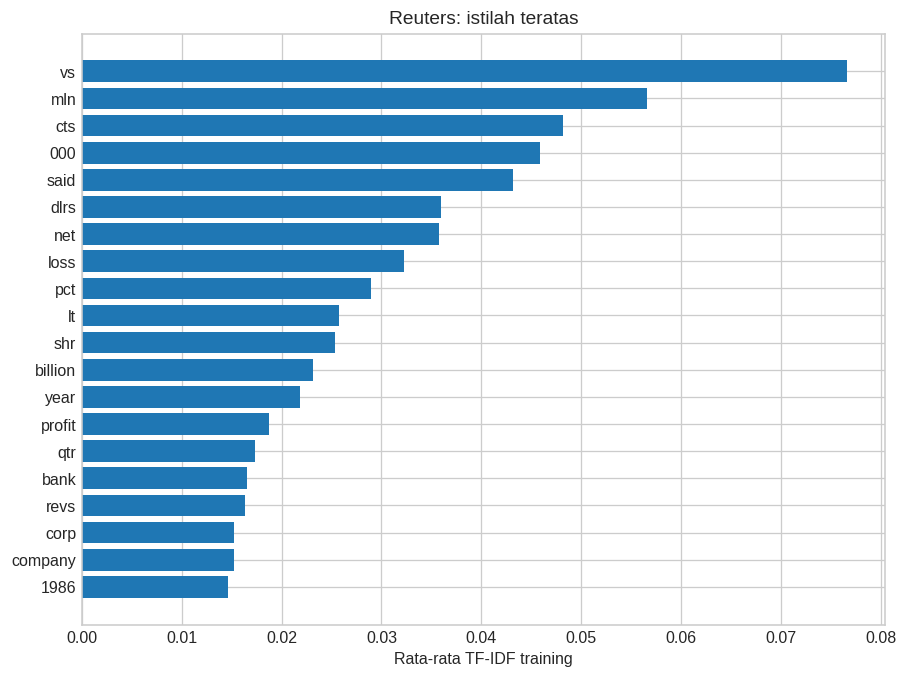

In [4]:
rids=sorted(reuters.fileids()); rt=np.array([reuters.raw(fid) for fid in rids],dtype=object)
Rtr,Rte=train_test_split(rt,test_size=.5,random_state=SEED)
print('Artikel dengan >1 kategori:',sum(len(reuters.categories(fid))>1 for fid in rids))
bow=CountVectorizer(); Rb=bow.fit_transform(Rtr); Rb_test=bow.transform(Rte)
tfidf=TfidfVectorizer(); Rt=tfidf.fit_transform(Rtr); Rt_test=tfidf.transform(Rte)
display(pd.DataFrame([{'vectorizer':n,'train_rows':m.shape[0],'features':m.shape[1],
    'nonzero':m.nnz,'sparse_MiB':(m.data.nbytes+m.indices.nbytes+m.indptr.nbytes)/2**20,
    'dense_float64_MiB':np.prod(m.shape)*8/2**20} for n,m in [('BoW',Rb),('TF-IDF',Rt)]]))
vis=TfidfVectorizer(stop_words='english'); V=vis.fit_transform(Rtr)
means=np.asarray(V.mean(axis=0)).ravel(); top=np.argsort(means)[-20:]
fig,ax=plt.subplots(figsize=(8,6)); ax.barh(vis.get_feature_names_out()[top],means[top])
ax.set(xlabel='Rata-rata TF-IDF training',title='Reuters: istilah teratas'); plt.tight_layout(); plt.show()

## 4. Brown: n-gram dan Part-of-Speech
N-gram mempertahankan konteks lokal: unigram `not` dan `good` terpisah, sedangkan bigram `not good` menangkap pasangan. Biayanya adalah vocabulary lebih besar dan sparsity meningkat. `min_df`, `max_df`, serta `max_features` dapat mengendalikan ukuran, tetapi harus ditetapkan atau dipilih pada training.

POS tagging memberi peran gramatikal seperti noun (NN), verb (VB) dan adjective (JJ). Tagger sendiri adalah model yang dapat salah dan bergantung bahasa/domain. Sesuai sumber, empat kalimat dari dua kategori Brown hanya dipakai untuk demonstrasi ekstraksi fitur; jumlah ini tidak memadai untuk klaim klasifikasi. POS frekuensi dihitung setelah tagging dalam konteks kalimat, kemudian stopwords dikeluarkan untuk tampilan.

Contoh n-gram (20 pertama): ['also', 'also led', 'direction', 'direction of', 'have', 'have also', 'he', 'he was', 'her', 'in', 'in the', 'led', 'led the', 'nation', 'nation in', 'of', 'of her', 'of welfare', 'rid', 'rid of']
Contoh pasangan token/POS: [('They', 'PRP'), ('have', 'VBP'), ('also', 'RB'), ('led', 'VBN'), ('the', 'DT'), ('nation', 'NN'), ('in', 'IN'), ('the', 'DT')]
Contoh bigram bertag: [(('They', 'PRP'), ('have', 'VBP')), (('have', 'VBP'), ('also', 'RB')), (('also', 'RB'), ('led', 'VBN'))]
Contoh pasangan token/POS: [('He', 'PRP'), ('was', 'VBD'), ('well', 'RB'), ('rid', 'JJ'), ('of', 'IN'), ('her', 'PRP'), ('.', '.')]
Contoh bigram bertag: [(('He', 'PRP'), ('was', 'VBD')), (('was', 'VBD'), ('well', 'RB')), (('well', 'RB'), ('rid', 'JJ'))]


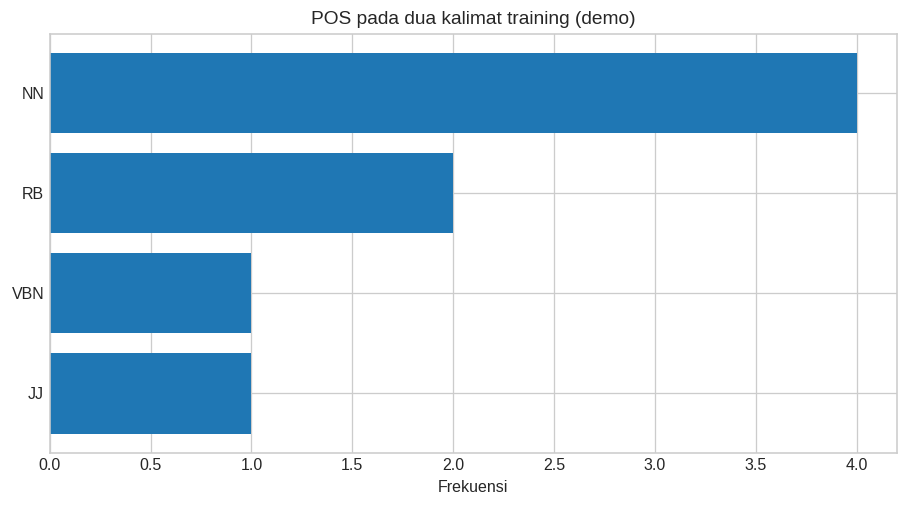

In [5]:
small=[]; small_y=[]
for j,category in enumerate(brown.categories()[:2]):
    for sent in brown.sents(categories=category)[:2]:
        small.append(' '.join(sent)); small_y.append(j)
Bt,Bv,bt,bv=train_test_split(small,small_y,test_size=.5,stratify=small_y,random_state=SEED)
ngrams=CountVectorizer(ngram_range=(1,2)); B=ngrams.fit_transform(Bt)
print('Contoh n-gram (20 pertama):',ngrams.get_feature_names_out()[:20].tolist())
stop=set(stopwords.words('english')); tag_counts=Counter()
for sentence in Bt:
    tagged=nltk.pos_tag(nltk.word_tokenize(sentence))
    print('Contoh pasangan token/POS:',tagged[:8])
    print('Contoh bigram bertag:',list(nltk.ngrams(tagged,2))[:3])
    tag_counts.update(tag for word,tag in tagged if word.lower() not in stop and word.isalpha())
tags,values=zip(*tag_counts.most_common(10))
fig,ax=plt.subplots(); ax.barh(tags[::-1],values[::-1]); ax.set(xlabel='Frekuensi',title='POS pada dua kalimat training (demo)')
plt.tight_layout(); plt.show()

## 5. Klasifikasi dokumen Brown: NB, SVM dan logistic
Brown terdiri dari 500 dokumen dan 15 genre. Genre dengan sedikit dokumen membuat recall/macro F1 sulit diperkirakan secara stabil. Audit distribusi di bawah mengoreksi anggapan bahwa semua kategori mempunyai lebih dari 20 sampel.

**Multinomial Naive Bayes** menggabungkan prior kelas dan kontribusi term dengan asumsi independensi fitur bersyarat kelas; smoothing mencegah peluang nol. TF-IDF nonnegatif dapat dipakai sebagai bobot meskipun bukan hitungan integer murni. **SVC** memaksimalkan margin; resep sumber menggunakan kernel default RBF. **Logistic regression** mempelajari probabilitas melalui log-loss. Untuk teks besar, linear classifier sering lebih efisien daripada RBF SVC.

Pipeline memastikan vocabulary tidak bocor. Tiga model merupakan perbandingan tetap pada split 50/50 sumber; hasil test tidak digunakan untuk memilih hyperparameter. Macro F1 memberi bobot sama untuk semua genre, weighted F1 mengutamakan genre dengan support besar. Nilai nol pada kelas yang tak pernah diprediksi tetap ditampilkan, bukan diubah menjadi skor satu.

,documents
adventure,29
belles_lettres,75
editorial,27
fiction,29
government,30
hobbies,36
humor,9
learned,80
lore,48
mystery,24


Kategori: 15 minimum dokumen per kategori: 6 empty: 0
Multinomial NB


,precision,recall,f1-score,support
adventure,0.0000,0.000,0.0000,15.0
belles_lettres,0.1729,1.000,0.2948,37.0
editorial,0.0000,0.000,0.0000,14.0
fiction,0.0000,0.000,0.0000,14.0
government,0.0000,0.000,0.0000,15.0
hobbies,0.0000,0.000,0.0000,18.0
humor,0.0000,0.000,0.0000,4.0
learned,0.5556,0.500,0.5263,40.0
lore,0.0000,0.000,0.0000,24.0
mystery,0.0000,0.000,0.0000,12.0


Overall accuracy: 0.2280 (n=250)
RBF SVC


,precision,recall,f1-score,support
adventure,0.4000,0.1333,0.2000,15.0
belles_lettres,0.2365,0.9459,0.3784,37.0
editorial,0.0000,0.0000,0.0000,14.0
fiction,0.3125,0.3571,0.3333,14.0
government,0.0000,0.0000,0.0000,15.0
hobbies,0.0000,0.0000,0.0000,18.0
humor,0.0000,0.0000,0.0000,4.0
learned,0.4242,0.7000,0.5283,40.0
lore,0.0000,0.0000,0.0000,24.0
mystery,0.0000,0.0000,0.0000,12.0


Overall accuracy: 0.3320 (n=250)
Logistic


,precision,recall,f1-score,support
adventure,1.0000,0.0667,0.1250,15.0
belles_lettres,0.2313,0.9189,0.3696,37.0
editorial,0.0000,0.0000,0.0000,14.0
fiction,0.0000,0.0000,0.0000,14.0
government,0.0000,0.0000,0.0000,15.0
hobbies,1.0000,0.0556,0.1053,18.0
humor,0.0000,0.0000,0.0000,4.0
learned,0.3766,0.7250,0.4957,40.0
lore,0.0000,0.0000,0.0000,24.0
mystery,0.0000,0.0000,0.0000,12.0


Overall accuracy: 0.3240 (n=250)


,accuracy,balanced_accuracy,macro_f1,weighted_f1
model,,,,
Dummy,0.160,0.0667,0.0184,0.0441
Multinomial NB,0.228,0.1000,0.0547,0.1278
RBF SVC,0.332,0.1875,0.1601,0.2451
Logistic,0.324,0.1790,0.1455,0.2274


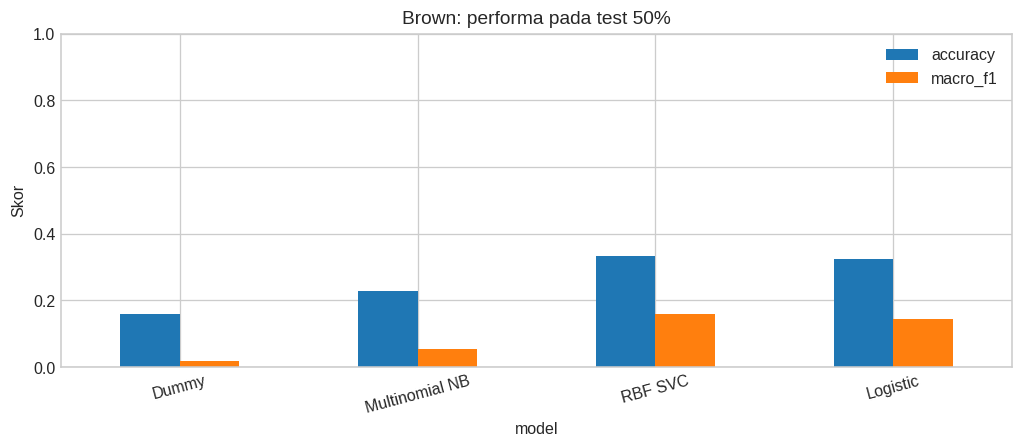

In [6]:
brown_ids=sorted(brown.fileids())
brown_texts=np.array([' '.join(brown.words(fid)) for fid in brown_ids],dtype=object)
brown_labels=np.array([brown.categories(fid)[0] for fid in brown_ids])
counts=pd.Series(brown_labels).value_counts().sort_index(); display(counts.rename('documents').to_frame())
print('Kategori:',len(counts),'minimum dokumen per kategori:',counts.min(), 'empty:',sum(not t.strip() for t in brown_texts))
Btr,Bte,yBtr,yBte=train_test_split(brown_texts,brown_labels,test_size=.5,stratify=brown_labels,random_state=SEED)
brown_models={'Dummy':DummyClassifier(strategy='most_frequent'),'Multinomial NB':MultinomialNB(),
    'RBF SVC':SVC(random_state=SEED),'Logistic':LogisticRegression(max_iter=2000,random_state=SEED)}
brown_fitted={}; rows=[]
for name,est in brown_models.items():
    pipe=make_pipeline(TfidfVectorizer(),est).fit(Btr,yBtr); brown_fitted[name]=pipe
    bp=pipe.predict(Bte); rows.append({'model':name,**metrics(yBte,bp), 'weighted_f1':f1_score(yBte,bp,average='weighted',zero_division=0)})
    if name!='Dummy':
        print(name); report(yBte,bp)
brown_results=pd.DataFrame(rows).set_index('model'); display(brown_results)
fig,ax=plt.subplots(figsize=(9,4)); brown_results[['accuracy','macro_f1']].plot.bar(ax=ax,rot=15,ylim=(0,1))
ax.set(title='Brown: performa pada test 50%',ylabel='Skor'); plt.tight_layout(); plt.show()

## 6. Multiclass One-vs-Rest dan One-vs-One
Untuk K kelas, OvR membutuhkan K model biner, sedangkan OvO memerlukan $K(K-1)/2$ model. Pada 15 genre, itu berarti 15 dan 105 classifier. OvO masing-masing melihat dua kelas sehingga dataset per-fit lebih kecil; tidak selalu berarti keseluruhan lebih cepat. Skor dan voting diubah menjadi satu kelas akhir.

Split 70/30 mengikuti resep strategi multiclass. Karena split ini berbeda dari Bagian 5, jangan membandingkan angka kedua tabel seolah-olah eksperimennya identik. Teks tetap dibaca melalui `words()` untuk menghilangkan anotasi POS yang terdapat dalam format mentah Brown.

In [7]:
B3t,B3v,b3t,b3v=train_test_split(brown_texts,brown_labels,test_size=.3,stratify=brown_labels,random_state=SEED)
strategies={'OvR':OneVsRestClassifier(LogisticRegression(solver='liblinear',max_iter=2000,random_state=SEED),n_jobs=1),
            'OvO':OneVsOneClassifier(LogisticRegression(solver='liblinear',max_iter=2000,random_state=SEED),n_jobs=1)}
strategy_rows=[]
for name,est in strategies.items():
    pipe=make_pipeline(TfidfVectorizer(),est); t0=time.perf_counter(); pipe.fit(B3t,b3t)
    sp=pipe.predict(B3v)
    strategy_rows.append({'strategy':name,'binary_models':len(pipe[-1].estimators_),'fit_seconds':time.perf_counter()-t0,**metrics(b3v,sp)})
    print(name); report(b3v,sp)
display(pd.DataFrame(strategy_rows))

OvR


,precision,recall,f1-score,support
adventure,1.0000,0.1111,0.2000,9.0
belles_lettres,0.2564,0.9091,0.4000,22.0
editorial,0.0000,0.0000,0.0000,8.0
fiction,0.5000,0.2222,0.3077,9.0
government,0.0000,0.0000,0.0000,9.0
hobbies,0.0000,0.0000,0.0000,11.0
humor,0.0000,0.0000,0.0000,3.0
learned,0.4000,0.7500,0.5217,24.0
lore,0.0000,0.0000,0.0000,14.0
mystery,0.0000,0.0000,0.0000,7.0


Overall accuracy: 0.3533 (n=150)
OvO


,precision,recall,f1-score,support
adventure,0.0000,0.0000,0.0000,9.0
belles_lettres,0.2059,0.9545,0.3387,22.0
editorial,0.0000,0.0000,0.0000,8.0
fiction,0.0000,0.0000,0.0000,9.0
government,0.0000,0.0000,0.0000,9.0
hobbies,0.0000,0.0000,0.0000,11.0
humor,0.0000,0.0000,0.0000,3.0
learned,0.4286,0.7500,0.5455,24.0
lore,0.0000,0.0000,0.0000,14.0
mystery,0.0000,0.0000,0.0000,7.0


Overall accuracy: 0.2800 (n=150)


,strategy,binary_models,fit_seconds,accuracy,balanced_accuracy,macro_f1
0,OvR,15,1.3345,0.3533,0.2058,0.1700
1,OvO,105,4.2816,0.2800,0.1359,0.0856


## 7. Evaluasi sentimen pada movie_reviews penuh
Resep ini memakai seluruh 2.000 review dengan test 50%. Stratifikasi ditambahkan untuk menjaga distribusi label. Probabilitas, confusion matrix, precision, recall dan F1 harus dibaca berdasarkan arti target: `pos` = sentimen positif, `neg` = sentimen negatif. Confusion matrix berisi **jumlah kesalahan/keberhasilan**, bukan langsung accuracy per kelas.

Model tidak melakukan pemahaman sarkasme, konteks panjang, atau negasi secara sempurna. Skor benchmark film tidak boleh dipakai untuk menyatakan kesiapan analisis sentimen semua media sosial. Dokumen duplikat/penulis yang sama lintas split perlu diperiksa bila identitas tersedia.

{'accuracy': 0.785, 'balanced_accuracy': np.float64(0.785), 'macro_f1': 0.7849946248656217, 'weighted_precision': 0.7850285028502851, 'weighted_recall': 0.785, 'weighted_f1': 0.7849946248656215}


,precision,recall,f1-score,support
neg,0.7822,0.790,0.7861,500.0
pos,0.7879,0.780,0.7839,500.0
macro avg,0.7850,0.785,0.7850,1000.0
weighted avg,0.7850,0.785,0.7850,1000.0


Overall accuracy: 0.7850 (n=1000)


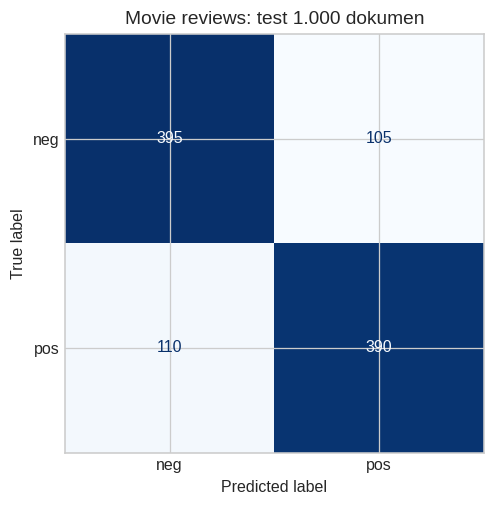

**Analisis hasil:** movie-review accuracy = 0.785. Perhatikan juga macro F1 dan jenis kesalahan pada confusion matrix. Angka Brown yang lebih rendah tidak berarti implementasi salah: tugasnya memiliki 15 kelas, dokumen lebih sedikit, dan kelas yang tidak seimbang.

In [8]:
Mtr,Mte,ymtr,ymte=train_test_split(movie_texts,movie_labels,test_size=.5,stratify=movie_labels,random_state=SEED)
sentiment=make_pipeline(TfidfVectorizer(),LogisticRegression(max_iter=2000,random_state=SEED)).fit(Mtr,ymtr)
mp=sentiment.predict(Mte)
print({**metrics(ymte,mp),'weighted_precision':precision_score(ymte,mp,average='weighted',zero_division=0),
       'weighted_recall':recall_score(ymte,mp,average='weighted',zero_division=0),'weighted_f1':f1_score(ymte,mp,average='weighted')})
report(ymte,mp)
fig,ax=plt.subplots(); ConfusionMatrixDisplay.from_predictions(ymte,mp,labels=['neg','pos'],cmap='Blues',colorbar=False,ax=ax)
ax.set_title('Movie reviews: test 1.000 dokumen'); plt.tight_layout(); plt.show()
display(Markdown(f'**Analisis hasil:** movie-review accuracy = {accuracy_score(ymte,mp):.3f}. '
    'Perhatikan juga macro F1 dan jenis kesalahan pada confusion matrix. Angka Brown yang lebih rendah tidak berarti implementasi salah: tugasnya memiliki 15 kelas, dokumen lebih sedikit, dan kelas yang tidak seimbang.'))

## 8. Latihan 1–2 — preprocessing, TF-IDF, n-gram
Kalimat latihan berikut mengikuti solusi sumber dan hanya dipakai untuk memahami transformasi, sehingga `fit_transform` pada semua empat kalimat tidak menjadi evaluasi supervised yang bocor. Lowercase eksplisit ditunjukkan meski vectorizer secara default sudah melakukan lowercase. Matriks dense hanya dicetak untuk contoh kecil ini.

In [9]:
ex1=['Data preprocessing is essential.','Vectorization transforms text.',
     'Clean data improves model performance.','Machine learning algorithms use numerical data.']
v1=TfidfVectorizer(); E1=v1.fit_transform([s.lower() for s in ex1])
display(pd.DataFrame(E1.toarray(),columns=v1.get_feature_names_out()).round(3))
ex2=['Feature extraction is crucial.','N-grams capture context.',
     'Models benefit from good features.','Contextual information enhances classification.']
v2=CountVectorizer(ngram_range=(1,2)); E2=v2.fit_transform(ex2)
print('Latihan 2 n-grams:',v2.get_feature_names_out().tolist())
print('Shape:',E2.shape)

,algorithms,clean,data,essential,improves,is,learning,machine,model,numerical,performance,preprocessing,text,transforms,use,vectorization
0,0.00,0.000,0.346,0.542,0.000,0.542,0.00,0.00,0.000,0.00,0.000,0.542,0.000,0.000,0.00,0.000
1,0.00,0.000,0.000,0.000,0.000,0.000,0.00,0.00,0.000,0.00,0.000,0.000,0.577,0.577,0.00,0.577
2,0.00,0.476,0.304,0.000,0.476,0.000,0.00,0.00,0.476,0.00,0.476,0.000,0.000,0.000,0.00,0.000
3,0.43,0.000,0.274,0.000,0.000,0.000,0.43,0.43,0.000,0.43,0.000,0.000,0.000,0.000,0.43,0.000


Latihan 2 n-grams: ['benefit', 'benefit from', 'capture', 'capture context', 'classification', 'context', 'contextual', 'contextual information', 'crucial', 'enhances', 'enhances classification', 'extraction', 'extraction is', 'feature', 'feature extraction', 'features', 'from', 'from good', 'good', 'good features', 'grams', 'grams capture', 'information', 'information enhances', 'is', 'is crucial', 'models', 'models benefit']
Shape: (4, 28)


## 9. Latihan 3 — memperbaiki evaluasi multiclass
Empat kalimat sumber memiliki empat label berbeda. Split 50/50 meninggalkan dua kelas test yang **tidak pernah ada pada training**; classifier closed-set tidak bisa mempelajari kelas yang belum dilihat. Skor dari eksperimen tersebut tidak mengukur kemampuan multiclass yang dimaksud. Vectorizer yang fit sebelum split juga melihat vocabulary test.

Perbaikan memakai tiga genre Brown (`news`, `hobbies`, `romance`) dengan beberapa dokumen per kelas. Split dilakukan terlebih dahulu, lalu Pipeline TF-IDF + logistic regression dituning pada 3-fold training-CV. Vocabulary dipelajari ulang pada tiap fold. Ini merupakan adaptasi latihan yang dinyatakan eksplisit, bukan klaim bahwa buku menyediakan lebih banyak contoh mini.

In [10]:
original_labels=np.array(['Economy','Sports','Technology','Politics'])
original_train,original_test=train_test_split(original_labels,test_size=.5,random_state=SEED)
print('Kelas test yang tidak ada pada training contoh asli:',sorted(set(original_test)-set(original_train)))
chosen=['news','hobbies','romance']; mask=np.isin(brown_labels,chosen)
Et,Ev,et,ev=train_test_split(brown_texts[mask],brown_labels[mask],test_size=.3,stratify=brown_labels[mask],random_state=SEED)
assert pd.Series(et).value_counts().min()>=3
ex_search=GridSearchCV(make_pipeline(TfidfVectorizer(),LogisticRegression(max_iter=2000,random_state=SEED)),
    {'logisticregression__C':[.1,1,10]},cv=StratifiedKFold(3,shuffle=True,random_state=SEED),
    scoring='f1_macro',n_jobs=1,error_score='raise').fit(Et,et)
print('Best training-CV macro F1:',ex_search.best_score_,ex_search.best_params_)
print('Final test:',metrics(ev,ex_search.predict(Ev))); report(ev,ex_search.predict(Ev))

Kelas test yang tidak ada pada training contoh asli: [np.str_('Politics'), np.str_('Sports')]
Best training-CV macro F1: 0.8969977553310887 {'logisticregression__C': 10}
Final test: {'accuracy': 0.9393939393939394, 'balanced_accuracy': np.float64(0.9393939393939394), 'macro_f1': 0.942857142857143}


,precision,recall,f1-score,support
hobbies,1.0000,0.8182,0.9000,11.0
news,0.8667,1.0000,0.9286,13.0
romance,1.0000,1.0000,1.0000,9.0
macro avg,0.9556,0.9394,0.9429,33.0
weighted avg,0.9475,0.9394,0.9385,33.0


Overall accuracy: 0.9394 (n=33)


## Ringkasan chapter
Vectorization adalah bagian yang dipelajari model, sehingga vocabulary dan IDF hanya boleh berasal dari training. BoW, TF-IDF, n-gram dan POS memberikan representasi yang berbeda. Brown memperlihatkan tantangan kelas kecil dan imbalance; movie_reviews memberi contoh sentimen biner. Evaluasi multiclass membutuhkan setiap kelas yang ingin dikenali memiliki contoh training yang memadai.

## Refleksi untuk dikerjakan sendiri
1. Mengapa menghapus “not” dapat merusak sentimen meskipun termasuk stopword?
2. Mengapa TF-IDF perlu berada di dalam Pipeline ketika melakukan CV?
3. Apa perbedaan multilabel Reuters dengan multiclass Brown?
4. Mengapa accuracy nol pada empat kalimat latihan sumber bukan bukti logistic regression selalu buruk?

## Referensi dan atribusi
- John Sukup. *scikit-learn Cookbook*, Third Edition. Packt Publishing, 2025. Kode pendamping Chapter 9 dan solusi latihan: [repository resmi](https://github.com/PacktPublishing/scikit-learn-Cookbook-Third-Edition/tree/c624b1279cf23a83273e806cede15cad0c9e5500).
- [NLTK: instalasi resource](https://www.nltk.org/data.html) dan [corpus readers](https://www.nltk.org/howto/corpus.html).
- [Text feature extraction](https://scikit-learn.org/1.8/modules/feature_extraction.html).
- [Naive Bayes](https://scikit-learn.org/1.8/modules/naive_bayes.html).
- Korpus: movie_reviews (Pang & Lee / Cornell), Reuters-21578 (Reuters), Brown (Brown University), tersedia melalui NLTK; lihat README masing-masing resource.
- Kode sumber pendamping berlisensi MIT; teks lisensi dipertahankan pada `THIRD_PARTY_NOTICES.md`. Penjelasan, koreksi metodologi, dan eksperimen tambahan pada notebook ini merupakan adaptasi belajar berbantuan AI. Baca, jalankan ulang, dan tulis refleksi pribadi sebelum menyerahkan tugas; jangan menyatakan bagian berbantuan AI sebagai pekerjaan mandiri tanpa mengikuti kebijakan kelas.